In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
print(sys.path[0])

/home/benjamin-rodriguez/Desktop/PredictionMarkets


In [2]:
from analysis.calibration import build_calibration_data, calibration_curve, plot_calibration

calibration_data = build_calibration_data(horizon_days=2, wiggle_hours=48)
print(calibration_data)

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 2700 resolved markets, 24 with usable observation, 2676 dropped (no snapshot in window)
   market_id  observation_price                 observation_time  \
0    1652706             0.7750 2026-06-15 22:18:18.807789+00:00   
1    1972155             0.8800 2026-06-15 22:18:18.782887+00:00   
2    2008485             0.9910 2026-06-15 22:18:18.775226+00:00   
3    2365092             0.0015 2026-06-15 22:18:18.759608+00:00   
4    2468320             0.9100 2026-06-15 22:18:18.784348+00:00   
5     666598             0.9875 2026-06-15 22:18:18.775157+00:00   
6     679651             0.0015 2026-06-15 22:18:18.779812+00:00   
7     679653             0.9755 2026-06-15 22:18:18.779817+00:00   
8     679654             0.0210 2026-06-15 22:18:18.779866+00:00   
9     679689             0.0885 2026-06-15 22:18:18.779963+00:00   
10    679693             0.8875 2026-06-15 22:18:18.779971+00:00   
11    679718             0.1755 2026-06-15 22:18:18.780049+00:00   
12    679720  

In [3]:
import pandas as pd
from analysis.calibration import build_calibration_data

# see what variables have most data in order to write code that we can use later. 

def sweep_horizon_wiggle(
    horizons: list[float],
    wiggles: list[float],
) -> pd.DataFrame:
    """
    Try every (horizon, wiggle) combo and report yield + quality metrics.

    Quality here = how many observations sit at a genuinely uncertain price
    (0.05 < p < 0.95) rather than already snapped to the boundary. High raw
    yield with low 'uncertain' count means you're mostly grabbing
    already-resolved markets — fine for code-testing, misleading for analysis.
    """
    results = []
    for h in horizons:
        for w in wiggles:
            df = build_calibration_data(horizon_days=h, wiggle_hours=w)
            if df.empty:
                results.append({
                    "horizon_days": h, "wiggle_hours": w,
                    "n_total": 0, "n_uncertain": 0,
                    "pct_uncertain": float("nan"),
                    "median_days_off_target": float("nan"),
                })
                continue

            uncertain = df[(df["observation_price"] > 0.05) & (df["observation_price"] < 0.95)]
            days_off = (df["days_before_resolution"] - h).abs().median()

            results.append({
                "horizon_days": h,
                "wiggle_hours": w,
                "n_total": len(df),
                "n_uncertain": len(uncertain),
                "pct_uncertain": round(100 * len(uncertain) / len(df), 1),
                "median_days_off_target": round(days_off, 3),
            })

    out = pd.DataFrame(results).sort_values(["horizon_days", "wiggle_hours"])
    return out

In [4]:
horizons = [0.5, 1, 2, 3, 5, 7]
wiggles  = [6, 12, 24, 48]

sweep = sweep_horizon_wiggle(horizons, wiggles)
print(sweep.to_string(index=False))

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 2700 resolved markets, 21 with usable observation, 2679 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 2700 resolved markets, 23 with usable observation, 2677 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


...

[calibration] 2700 resolved markets, 0 with usable observation, 2700 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 2700 resolved markets, 0 with usable observation, 2700 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 2700 resolved markets, 0 with usable observation, 2700 dropped (no snapshot in window)
 horizon_days  wiggle_hours  n_total  n_uncertain  pct_uncertain  median_days_off_target
          0.5             6       21            9           42.9                   0.003
          0.5            12       23            9           39.1                   0.003
          0.5            24       23            9           39.1                   0.003
          0.5            48       24            9           37.5                   0.003
          1.0             6       20            8           40.0                   0.003
          1.0            12       21            9           42.9                   0.003
          1.0            24       24           10           41.7                   0.003
          1.0            48       24           10           41.7                   0.003
          2.0             6        5            0            0.0                   0.049
         

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 2700 resolved markets, 24 with usable observation, 2676 dropped (no snapshot in window)
          bin  mean_price  empirical_yes  n       se
(-0.001, 0.1]    0.005944            0.0  9 0.000000
   (0.2, 0.3]    0.255250            0.5  2 0.353553
   (0.3, 0.4]    0.320000            0.0  1 0.000000
   (0.5, 0.6]    0.582500            1.0  1 0.000000
   (0.6, 0.7]    0.669250            0.5  2 0.353553
   (0.8, 0.9]    0.842500            1.0  2 0.000000
   (0.9, 1.0]    0.977929            1.0  7 0.000000


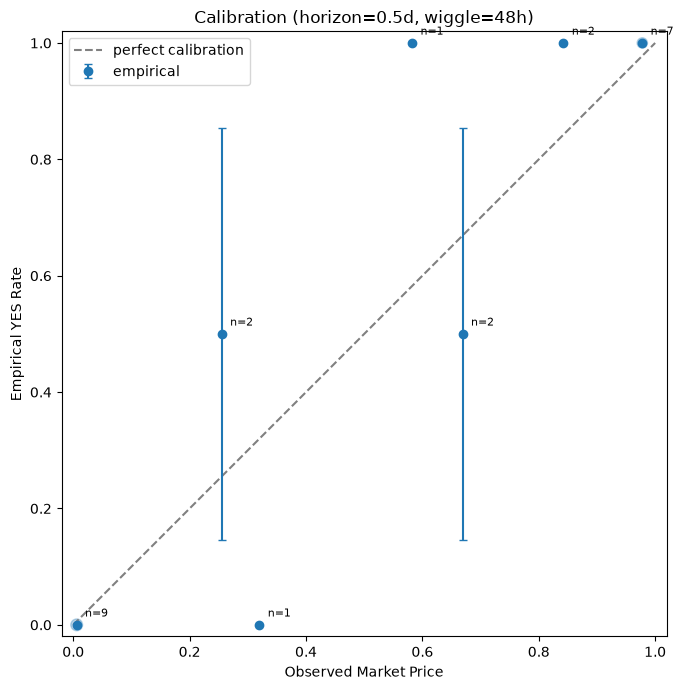

In [6]:
horizon, tol = 0.5, 48

calibration_data = build_calibration_data(horizon_days=horizon, wiggle_hours=tol)

curve = calibration_curve(calibration_data, n_bins=10)
print(curve[["bin", "mean_price", "empirical_yes", "n", "se"]].to_string(index=False))

plot_calibration(curve, title=f"Calibration (horizon={horizon}d, wiggle={tol}h)")

